In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
weight_url = "https://www.ssbwiki.com/Weight"
run_url = "https://www.ssbwiki.com/Run"
air_url = "https://www.ssbwiki.com/Air_speed"
fall_url = "https://www.ssbwiki.com/Falling_speed"
jump_url = "https://www.ssbwiki.com/Jump"

weight_tables = pd.read_html(weight_url)
run_tables = pd.read_html(run_url)
air_tables = pd.read_html(air_url)
fall_tables = pd.read_html(fall_url)
jump_tables = pd.read_html(jump_url)

print("Weight tables:", len(weight_tables))
print("Run tables:", len(run_tables))
print("Air tables:", len(air_tables))
print("Fall tables:", len(fall_tables))
print("Jump tables:", len(jump_tables))

Weight tables: 10
Run tables: 6
Air tables: 9
Fall tables: 6
Jump tables: 11


In [3]:
for i, table in enumerate(weight_tables):
    print("WEIGHT TABLE", i)
    print(table.head())
    print()

WEIGHT TABLE 0
  Rank          Character  Weight (coded)  Weight (comparison)
0    1        Donkey Kong            0.84              138.095
1    2              Samus            0.92              117.391
2    3              Yoshi            0.93              115.054
3  NaN  Giant Donkey Kong            0.93              115.054
4  4-5     Captain Falcon            0.96              108.333

WEIGHT TABLE 1
  Rank          Character  Weight (coded)  Weight (comparison)
0    1        Donkey Kong            0.83              140.964
1    2              Samus            0.92              117.391
2    3              Yoshi            0.93              115.054
3  NaN  Giant Donkey Kong            0.93              115.054
4  4-5     Captain Falcon            0.96              108.333

WEIGHT TABLE 2
  Rank          Character  Weight (coded)  Weight (comparison)
0    1        Donkey Kong            0.83              140.964
1    2               Link            0.90              122.222
2    3  

In [4]:
for i, table in enumerate(run_tables):
    print("RUN TABLE", i)
    print(table.head())
    print()

RUN TABLE 0
   Rank       Character  Initial Dash  Run speed
0     1  Captain Falcon            80         70
1     2             Fox            61         60
2     3         Pikachu            60         55
3     4           Samus            56         54
4     5           Yoshi            40         50

RUN TABLE 1
   Rank       Character  Initial Dash  Run speed
0     1  Captain Falcon            80         75
1     2             Fox            81         60
2     3         Pikachu            60         55
3     4           Samus            56         54
4     5           Yoshi            40         50

RUN TABLE 2
  Rank       Character  Initial Dash  Run Speed  Dash Frames  \
0    1  Captain Falcon           2.0        2.3           15   
1    2             Fox           1.9        2.2           11   
2    3         Pikachu           1.8        1.8           13   
3    4           Sheik           1.7        1.8            7   
4    5           Marth           1.5        1.8       

In [5]:
for i, table in enumerate(air_tables):
    print("AIR TABLE", i)
    print(table.head())
    print()

AIR TABLE 0
  Rank   Character  Air speed
0    1       Yoshi       40.0
1    2     Pikachu       37.5
2    3         Fox       36.0
3    4  Jigglypuff       35.0
4  5-6        Link       31.0

AIR TABLE 1
  Rank   Character  Air speed
0    1       Yoshi       44.0
1    2     Pikachu       37.5
2    3         Fox       36.0
3    4  Jigglypuff       35.0
4  5-6        Link       31.0

AIR TABLE 2
  Rank       Character  Air speed
0    1           Yoshi       44.0
1    2         Pikachu       37.5
2    3             Fox       36.0
3    4      Jigglypuff       35.0
4    5  Captain Falcon       31.0

AIR TABLE 3
  Rank   Character  Air speed
0    1       Yoshi       44.0
1    2     Pikachu       37.5
2    3        Link       37.0
3    4         Fox       36.0
4    5  Jigglypuff       35.0

AIR TABLE 4
  Rank       Character  Air speed
0    1      Jigglypuff       1.35
1  NaN     Giga Bowser       1.22
2  2-3           Yoshi       1.20
3  2-3          Mewtwo       1.20
4    4  Captain Falcon

In [6]:
for i, table in enumerate(fall_tables):
    print("FALL TABLE", i)
    print(table.head())
    print()

FALL TABLE 0
  Rank          Character  Falling Speed
0  NaN        Metal Mario            100
1  NaN  Giant Donkey Kong             72
2    1               Link             64
3  2-3                Fox             60
4  2-3     Captain Falcon             60

FALL TABLE 1
  Rank          Character  Falling Speed
0  NaN        Metal Mario            100
1  NaN  Giant Donkey Kong             72
2    1     Captain Falcon             66
3    2               Link             64
4    3                Fox             60

FALL TABLE 2
  Rank       Character  Falling Speed
0    1           Falco            3.1
1    2  Captain Falcon            2.9
2    3             Fox            2.8
3  4-5     Donkey Kong            2.4
4  4-5             Roy            2.4

FALL TABLE 3
  Rank       Character  Falling Speed
0  NaN     Giga Bowser          2.500
1  NaN       Wario-Man          2.200
2    1     King Dedede          1.950
3    2  Captain Falcon          1.837
4    3             Fox          1.8

In [7]:
for i, table in enumerate(jump_tables):
    print("JUMP TABLE", i)
    print(table.head())
    print()

JUMP TABLE 0
  Rank Character  Frames
0  1-7       Fox       3
1  1-7     Kirby       3
2  1-7     Luigi       3
3  1-7     Mario       3
4  1-7      Ness       3

JUMP TABLE 1
  Rank     Character  Frames
0  1-7           Fox       3
1  1-7  Ice Climbers       3
2  1-7         Kirby       3
3  1-7         Pichu       3
4  1-7       Pikachu       3

JUMP TABLE 2
   Rank     Character  Frames
0  1-10    Diddy Kong       4
1  1-10           Fox       4
2  1-10  Ice Climbers       4
3  1-10         Kirby       4
4  1-10   Meta Knight       4

JUMP TABLE 3
   Rank   Character Frames
0  1-13   Bayonetta      4
1  1-13       Cloud      4
2  1-13  Diddy Kong      4
3  1-13   Duck Hunt      4
4  1-13         Fox      4

JUMP TABLE 4
   Rank       Character  Jump multiplier  Jump base  Min height  Max height
0     1           Luigi             0.70       30.0     1038.50      1718.0
1     2  Captain Falcon             1.00       25.0      855.80      1569.0
2     3           Samus             0

In [8]:
weight_df = weight_tables[4][["Character", "Weight"]].copy()
weight_df.columns = ["fighter", "weight"]

run_df = run_tables[5][["Character", "Run Speed"]].copy()
run_df.columns = ["fighter", "run_speed"]

air_df = air_tables[8][["Character", "Air speed"]].copy()
air_df.columns = ["fighter", "air_speed"]

fall_df = fall_tables[5][["Character", "Falling Speed"]].copy()
fall_df.columns = ["fighter", "fall_speed"]

jump_df = jump_tables[10][["Character", "Full Hop"]].copy()
jump_df.columns = ["fighter", "full_hop"]

In [16]:
smash_df = weight_df.merge(
    run_df,
    on="fighter",
    how="inner"
)

smash_df = smash_df.merge(
    air_df,
    on="fighter",
    how="inner"
)

smash_df = smash_df.merge(
    fall_df,
    on="fighter",
    how="inner"
)

smash_df = smash_df.merge(
    jump_df,
    on="fighter",
    how="inner"
)

print("Fighters after merging:", len(smash_df))

smash_df.head(10)

Fighters after merging: 88


,fighter,weight,run_speed,air_speed,fall_speed,full_hop
0,Bowser,135,1.971,1.155,1.77,33.00
1,King K. Rool,133,1.485,0.945,1.70,33.00
2,Donkey Kong,127,1.873,1.208,1.63,34.00
3,King Dedede,127,1.496,0.735,1.95,32.85
4,Ganondorf,118,1.340,0.830,1.65,25.49
5,Charizard,116,2.200,1.103,1.52,32.00
6,Incineroar,116,1.180,0.880,1.76,31.60
7,Kazuya,113,1.550,0.890,1.70,18.00
8,Piranha Plant,112,1.720,1.000,1.95,37.40
9,Samus,108,1.654,1.103,1.33,37.00


In [10]:
def largest_table_with_column(tables, column_name):
    possible = []

    for i, table in enumerate(tables):
        if column_name in table.columns:
            possible.append((i, len(table)))

    print(column_name, possible)

    best_index = max(possible, key=lambda x: x[1])[0]

    print("Using table:", best_index)
    print("Rows:", len(tables[best_index]))

    return tables[best_index]

In [11]:
weight_raw = largest_table_with_column(weight_tables, "Weight")
run_raw = largest_table_with_column(run_tables, "Run Speed")
air_raw = largest_table_with_column(air_tables, "Air speed")
fall_raw = largest_table_with_column(fall_tables, "Falling Speed")
jump_raw = largest_table_with_column(jump_tables, "Full Hop")

Weight [(3, 30), (4, 30), (6, 42), (8, 62), (9, 91)]
Using table: 9
Rows: 91
Run Speed [(2, 26), (3, 41), (4, 68), (5, 90)]
Using table: 5
Rows: 90
Air speed [(0, 14), (1, 14), (2, 14), (3, 14), (4, 27), (5, 27), (6, 42), (7, 71), (8, 90)]
Using table: 8
Rows: 90
Falling Speed [(0, 14), (1, 14), (2, 30), (3, 42), (4, 62), (5, 90)]
Using table: 5
Rows: 90
Full Hop [(9, 58), (10, 89)]
Using table: 10
Rows: 89


In [14]:
weight_df = weight_raw[["Character", "Weight"]].copy()
weight_df.columns = ["fighter", "weight"]

run_df = run_raw[["Character", "Run Speed"]].copy()
run_df.columns = ["fighter", "run_speed"]

air_df = air_raw[["Character", "Air speed"]].copy()
air_df.columns = ["fighter", "air_speed"]

fall_df = fall_raw[["Character", "Falling Speed"]].copy()
fall_df.columns = ["fighter", "fall_speed"]

jump_df = jump_raw[["Character", "Full Hop"]].copy()
jump_df.columns = ["fighter", "full_hop"]

In [15]:
weight_df = weight_raw[["Character", "Weight"]].copy()
weight_df.columns = ["fighter", "weight"]

run_df = run_raw[["Character", "Run Speed"]].copy()
run_df.columns = ["fighter", "run_speed"]

air_df = air_raw[["Character", "Air speed"]].copy()
air_df.columns = ["fighter", "air_speed"]

fall_df = fall_raw[["Character", "Falling Speed"]].copy()
fall_df.columns = ["fighter", "fall_speed"]

jump_df = jump_raw[["Character", "Full Hop"]].copy()
jump_df.columns = ["fighter", "full_hop"]

In [18]:
high_tier_fighters = [
    "Sonic",
    "Steve",
    "Snake",
    "Mr. Game & Watch",
    "R.O.B.",
    "Pyra/Mythra",
    "Joker",
    "Kazuya",
    "Fox",
    "Cloud",
    "Peach/Daisy",
    "Yoshi",
    "Samus/Dark Samus",
    "Min Min",
    "Roy",
    "Diddy Kong",
    "Pikachu",
    "Palutena",
    "Wolf",
    "Mario",
    "Shulk",
    "Lucina",
    "Pac-Man",
    "Zero Suit Samus",
    "Greninja",
    "Young Link",
    "Chrom",
    "Sheik",
    "Terry",
    "Wario",
    "Mega Man",
    "Sephiroth",
    "Bayonetta",
    "Corrin"
]

In [19]:
high_tier_aliases = {
    "Pyra": 1,
    "Mythra": 1,
    "Peach": 1,
    "Daisy": 1,
    "Samus": 1,
    "Dark Samus": 1
}

smash_df["high_tier"] = smash_df["fighter"].apply(
    lambda fighter: 1
    if fighter in high_tier_fighters or fighter in high_tier_aliases
    else 0
)

smash_df[["fighter", "high_tier"]].head(20)

,fighter,high_tier
0,Bowser,0
1,King K. Rool,0
2,Donkey Kong,0
3,King Dedede,0
4,Ganondorf,0
5,Charizard,0
6,Incineroar,0
7,Kazuya,1
8,Piranha Plant,0
9,Samus,1


In [20]:
print(smash_df["high_tier"].value_counts())

print("\nHigh-tier fighters found:")
print(smash_df[smash_df["high_tier"] == 1]["fighter"].tolist())

high_tier
0    51
1    37
Name: count, dtype: int64

High-tier fighters found:
['Kazuya', 'Samus', 'Dark Samus', 'Terry', 'Wario', 'Snake', 'R.O.B.', 'Yoshi', 'Min Min', 'Mega Man', 'Cloud', 'Mario', 'Corrin', 'Pyra', 'Shulk', 'Roy', 'Chrom', 'Pac-Man', 'Joker', 'Wolf', 'Steve', 'Mythra', 'Palutena', 'Lucina', 'Diddy Kong', 'Peach', 'Daisy', 'Young Link', 'Greninja', 'Sonic', 'Bayonetta', 'Zero Suit Samus', 'Pikachu', 'Sephiroth', 'Sheik', 'Fox', 'Mr. Game & Watch']


In [21]:
features = [
    "weight",
    "run_speed",
    "air_speed",
    "fall_speed",
    "full_hop"
]

X = smash_df[features]
y = smash_df["high_tier"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training fighters:", len(X_train))
print("Testing fighters:", len(X_test))

Training fighters: 66
Testing fighters: 22


In [22]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy, 3))

Model Accuracy: 0.636


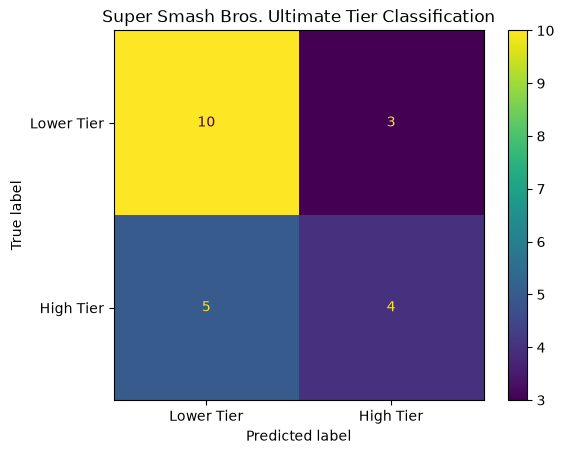

In [23]:
cm = confusion_matrix(y_test, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lower Tier", "High Tier"]
)

disp.plot()

plt.title("Super Smash Bros. Ultimate Tier Classification")
plt.show()

In [24]:
results = smash_df.loc[X_test.index].copy()

results["actual"] = y_test
results["predicted"] = predictions

wrong_predictions = results[
    results["actual"] != results["predicted"]
]

wrong_predictions[
    [
        "fighter",
        "weight",
        "run_speed",
        "air_speed",
        "fall_speed",
        "full_hop",
        "actual",
        "predicted"
    ]
].head(5)

,fighter,weight,run_speed,air_speed,fall_speed,full_hop,actual,predicted
37,Shulk,97,1.672,1.113,1.58,33.50,1,0
9,Samus,108,1.654,1.103,1.33,37.00,1,0
10,Dark Samus,108,1.654,1.103,1.33,37.00,1,0
19,R.O.B.,106,1.725,1.134,1.60,38.00,1,0
72,Falco,82,1.619,0.977,1.80,50.51,0,1


In [25]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
1,run_speed,0.362049
4,full_hop,0.267312
3,fall_speed,0.245057
0,weight,0.125583
2,air_speed,0.000000


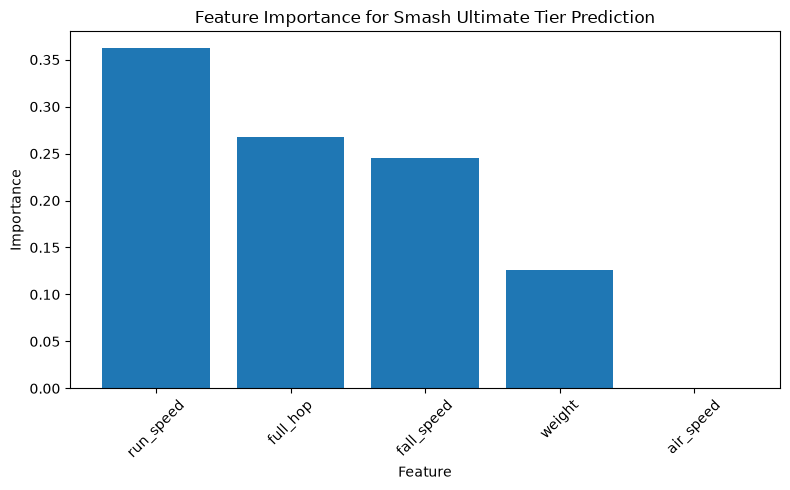

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance for Smash Ultimate Tier Prediction")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

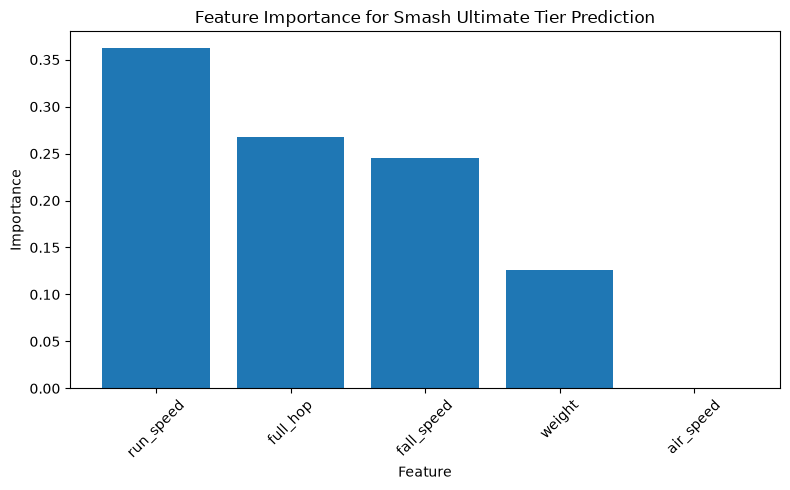

In [27]:
# Save feature importance figure
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance for Smash Ultimate Tier Prediction")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "smash_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
smash_df.to_csv(
    "smash_ultimate_classification_dataset.csv",
    index=False
)

wrong_predictions.head(5).to_csv(
    "smash_wrong_predictions.csv",
    index=False
)

print("Files saved.")

Files saved.


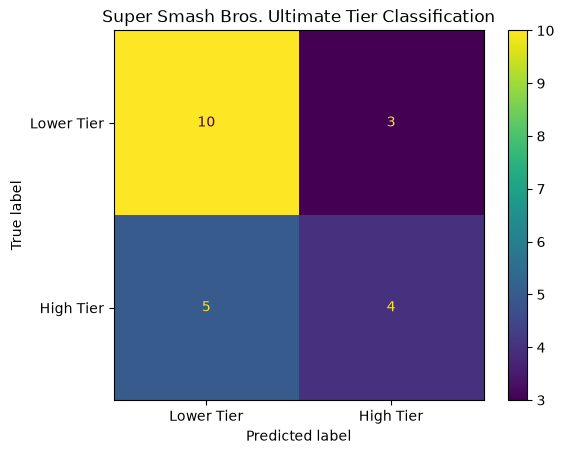

In [30]:
cm = confusion_matrix(y_test, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lower Tier", "High Tier"]
)

disp.plot()

plt.title("Super Smash Bros. Ultimate Tier Classification")

plt.savefig(
    "smash_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
print("Total fighters:", len(smash_df))
print("Duplicate fighter names:", smash_df["fighter"].duplicated().sum())

print("\nMissing values:")
print(
    smash_df[
        [
            "weight",
            "run_speed",
            "air_speed",
            "fall_speed",
            "full_hop",
            "high_tier"
        ]
    ].isna().sum()
)

print("\nClass counts:")
print(smash_df["high_tier"].value_counts())

print("\nAccuracy check:")
print("Correct predictions:", (y_test == predictions).sum())
print("Total test predictions:", len(y_test))
print("Accuracy:", round((y_test == predictions).mean(), 3))

Total fighters: 88
Duplicate fighter names: 0

Missing values:
weight        0
run_speed     0
air_speed     0
fall_speed    0
full_hop      0
high_tier     0
dtype: int64

Class counts:
high_tier
0    51
1    37
Name: count, dtype: int64

Accuracy check:
Correct predictions: 14
Total test predictions: 22
Accuracy: 0.636


In [33]:
smash_df.to_csv(
    "smash_ultimate_classification_dataset.csv",
    index=False
)

wrong_predictions.head(5).to_csv(
    "smash_wrong_predictions.csv",
    index=False
)

feature_importance.to_csv(
    "smash_feature_importance.csv",
    index=False
)

print("All files saved.")

All files saved.
